# Cyclistic Bike-Share — Analysis Notebook

**Business task:** identify how annual members and casual riders use Cyclistic bikes differently, and what that implies for converting casual riders into annual members.

**Input:** `03_Clean_Data/cyclistic_clean.csv` (output of `16_clean_cyclistic_data.py`, validated by `17_validate_clean_data.py`).

**Structure**
1. Load and integrity re-check
2. Reconciliation with the PostgreSQL results (`05_SQL`)
3. Q1 — How do members and casual riders use bikes differently?
4. Duration outliers: how sensitive are the conclusions?
5. Where do casual riders ride? Stations and round trips
6. Q2/Q3 — What this implies for conversion and digital marketing
7. Findings summary and limitations

Descriptive analysis only. The dataset has no rider IDs, prices, trip purpose or demographics, so nothing here *proves* why riders behave as they do or that anyone would convert.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import Markdown, display

PROJECT = Path.cwd().parent                      # notebook lives in 06_Python/
CLEAN_FILE = PROJECT / "03_Clean_Data" / "cyclistic_clean.csv"
CHART_DIR = PROJECT / "08_Visualizations" / "analysis_charts"
CHART_DIR.mkdir(parents=True, exist_ok=True)

EXPECTED_ROWS = 6_115_947                        # from 17_validate_clean_data.py

# Design tokens (validated two-series palette: blue = member, orange = casual)
COLOR = {"member": "#2a78d6", "casual": "#eb6834"}
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
ORDER = ["member", "casual"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})

def save(fig, name):
    fig.savefig(CHART_DIR / name, dpi=160, bbox_inches="tight")
    plt.show()

## 1. Load and integrity re-check

In [2]:
USECOLS = ["ride_id", "rideable_type", "started_at", "start_station_name", "start_station_id",
           "end_station_id", "member_casual", "source_file", "ride_length_minutes", "day_of_week"]
DTYPES = {"rideable_type": "category", "member_casual": "category", "source_file": "category",
          "day_of_week": "category", "start_station_id": "category", "end_station_id": "category",
          "start_station_name": "category"}

df = pd.read_csv(CLEAN_FILE, usecols=USECOLS, dtype=DTYPES)
# Timestamps carry 1-3 fractional-second digits, so parse explicitly as ISO8601
df["started_at"] = pd.to_datetime(df["started_at"], format="ISO8601")

# Integrity re-check (mirrors 17_validate_clean_data.py)
assert len(df) == EXPECTED_ROWS, f"Row count {len(df):,} != {EXPECTED_ROWS:,}"
assert df["ride_id"].is_unique, "Duplicate ride_id found"
assert set(df["member_casual"].unique()) == {"member", "casual"}
assert set(df["rideable_type"].unique()) == {"classic_bike", "electric_bike"}
assert (df["ride_length_minutes"] >= 0).all(), "Negative durations remain"
df = df.drop(columns="ride_id")

print(f"Rows: {len(df):,}  |  started_at: {df['started_at'].min()}  ->  {df['started_at'].max()}")

Rows: 6,115,947  |  started_at: 2025-08-30 23:10:32.607000  ->  2026-08-31 23:55:36.979000


In [3]:
# Derived analysis fields (definitions match 05_SQL/03_analysis.sql and 04_final_queries.sql)
df["hour"] = df["started_at"].dt.hour.astype("int8")
df["is_weekend"] = df["day_of_week"].isin(["Saturday", "Sunday"])
df["day_type"] = np.where(df["is_weekend"], "Weekend", "Weekday")

# Month comes from the source file (handles rides crossing month boundaries) - same as LEFT(source_file, 6)
df["analysis_month"] = df["source_file"].astype(str).str[:6]
SEASON = {"12": "Winter", "01": "Winter", "02": "Winter", "03": "Spring", "04": "Spring",
          "05": "Spring", "06": "Summer", "07": "Summer", "08": "Summer",
          "09": "Autumn", "10": "Autumn", "11": "Autumn"}
df["season"] = df["analysis_month"].str[4:6].map(SEASON)

df["duration_bucket"] = pd.cut(df["ride_length_minutes"], [-np.inf, 15, 30, 60, np.inf],
                               labels=["<15 min", "15-29 min", "30-59 min", "60+ min"], right=False)

commute_window = (~df["is_weekend"]) & (df["hour"].between(6, 9) | df["hour"].between(16, 19))
df["commute_like"] = commute_window & (df["ride_length_minutes"] < 30)
df["summer"] = df["season"].eq("Summer")
df["electric"] = df["rideable_type"].eq("electric_bike")
df.groupby("member_casual", observed=True).size()

member_casual
casual    2160353
member    3955594
dtype: int64

## 2. Reconciliation with the PostgreSQL results

The same metrics were computed independently in SQL (`02_exploration.sql`, `03_analysis.sql`, `04_final_queries.sql`).
If pandas and SQL disagree, one of them is wrong, so this check runs before anything is interpreted.

In [4]:
SQL_REFERENCE = {   # values reported by the SQL files on the cleaned table
    ("rides", "member"): 3_955_594, ("rides", "casual"): 2_160_353,
    ("median_min", "member"): 8.55, ("median_min", "casual"): 10.86,
    ("weekend_share", "member"): 23.34, ("weekend_share", "casual"): 37.27,
    ("electric_share", "member"): 68.06, ("electric_share", "casual"): 73.60,
    ("summer_rides", "member"): 1_486_524, ("summer_rides", "casual"): 1_013_268,
    ("commute_like_rides", "member"): 1_737_372, ("commute_like_rides", "casual"): 602_209,
}

g = df.groupby("member_casual", observed=True)
pandas_values = {}
for rider in ORDER:
    sub = g.get_group(rider)
    pandas_values[("rides", rider)] = len(sub)
    pandas_values[("median_min", rider)] = round(sub["ride_length_minutes"].median(), 2)
    pandas_values[("weekend_share", rider)] = round(sub["is_weekend"].mean() * 100, 2)
    pandas_values[("electric_share", rider)] = round(sub["electric"].mean() * 100, 2)
    pandas_values[("summer_rides", rider)] = int(sub["summer"].sum())
    pandas_values[("commute_like_rides", rider)] = int(sub["commute_like"].sum())

recon = pd.DataFrame({"sql": SQL_REFERENCE, "pandas": pandas_values})
recon["match"] = np.isclose(recon["sql"], recon["pandas"], atol=0.011)
display(recon)
assert recon["match"].all(), "pandas and SQL results disagree"
print("Reconciliation passed: pandas matches SQL on all checked metrics.")

sql      pandas  match
rides              member  3955594.00  3955594.00   True
                   casual  2160353.00  2160353.00   True
median_min         member        8.55        8.55   True
                   casual       10.86       10.86   True
weekend_share      member       23.34       23.34   True
                   casual       37.27       37.27   True
electric_share     member       68.06       68.06   True
                   casual       73.60       73.60   True
summer_rides       member  1486524.00  1486524.00   True
                   casual  1013268.00  1013268.00   True
commute_like_rides member  1737372.00  1737372.00   True
                   casual   602209.00   602209.00   True

Reconciliation passed: pandas matches SQL on all checked metrics.


## 3. Q1 — How do members and casual riders use bikes differently?

In [5]:
kpi = g.agg(
    rides=("member_casual", "size"),
    avg_min=("ride_length_minutes", "mean"),
    median_min=("ride_length_minutes", "median"),
    p90_min=("ride_length_minutes", lambda s: s.quantile(0.90)),
    weekend_pct=("is_weekend", lambda s: s.mean() * 100),
    electric_pct=("electric", lambda s: s.mean() * 100),
    summer_pct=("summer", lambda s: s.mean() * 100),
    commute_like_pct=("commute_like", lambda s: s.mean() * 100),
).loc[ORDER].round(2)
kpi["ride_share_pct"] = (kpi["rides"] / kpi["rides"].sum() * 100).round(2)
kpi.T

member_casual,member,casual
rides,3955594.00,2160353.00
avg_min,12.37,20.70
median_min,8.55,10.86
p90_min,23.31,35.83
weekend_pct,23.34,37.27
electric_pct,68.06,73.60
summer_pct,37.58,46.90
commute_like_pct,43.92,27.88
ride_share_pct,64.68,35.32


### 3.1 When: hour of day, weekday vs weekend

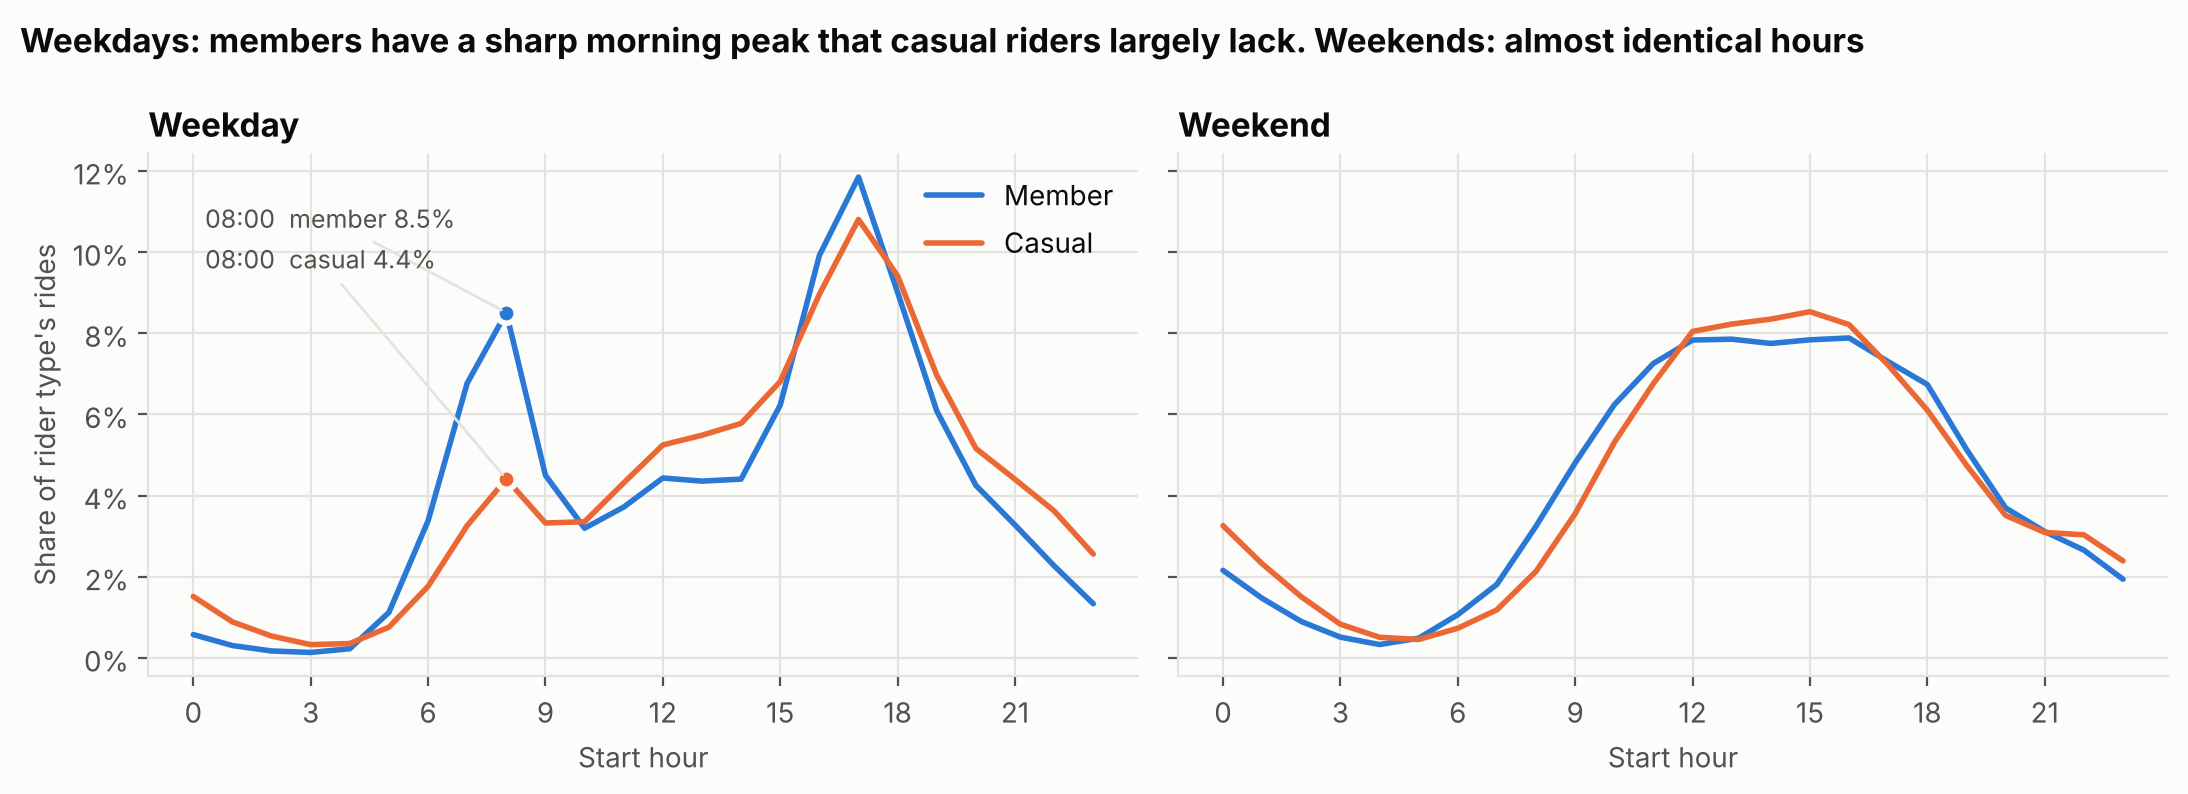

In [6]:
hourly = (df.groupby(["member_casual", "day_type", "hour"], observed=True).size()
            .rename("rides").reset_index())
hourly["share_pct"] = hourly["rides"] / hourly.groupby(["member_casual", "day_type"], observed=True)["rides"].transform("sum") * 100

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, dtype in zip(axes, ["Weekday", "Weekend"]):
    for rider in ORDER:
        s = hourly[(hourly.member_casual == rider) & (hourly.day_type == dtype)]
        ax.plot(s["hour"], s["share_pct"], color=COLOR[rider], lw=2, label=rider.capitalize(),
                solid_capstyle="round")
    ax.set_title(dtype)
    ax.set_xlabel("Start hour"); ax.set_xticks(range(0, 24, 3))
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))

# Label the one gap that matters: the weekday 08:00 peak
wk = hourly[(hourly.day_type == "Weekday") & (hourly.hour == 8)].set_index("member_casual")["share_pct"]
for rider in ORDER:
    axes[0].plot(8, wk[rider], "o", color=COLOR[rider], ms=7, mec=SURFACE, mew=2)
axes[0].annotate(f"08:00  member {wk['member']:.1f}%", (8, wk["member"]), xytext=(0.3, 10.6),
                 fontsize=9, color=INK2, arrowprops=dict(arrowstyle="-", color=GRID))
axes[0].annotate(f"08:00  casual {wk['casual']:.1f}%", (8, wk["casual"]), xytext=(0.3, 9.6),
                 fontsize=9, color=INK2, arrowprops=dict(arrowstyle="-", color=GRID))
axes[0].set_ylabel("Share of rider type's rides")
axes[0].legend(loc="upper right")
fig.suptitle("Weekdays: members have a sharp morning peak that casual riders largely lack. Weekends: almost identical hours",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
save(fig, "01_hourly_profile.png")

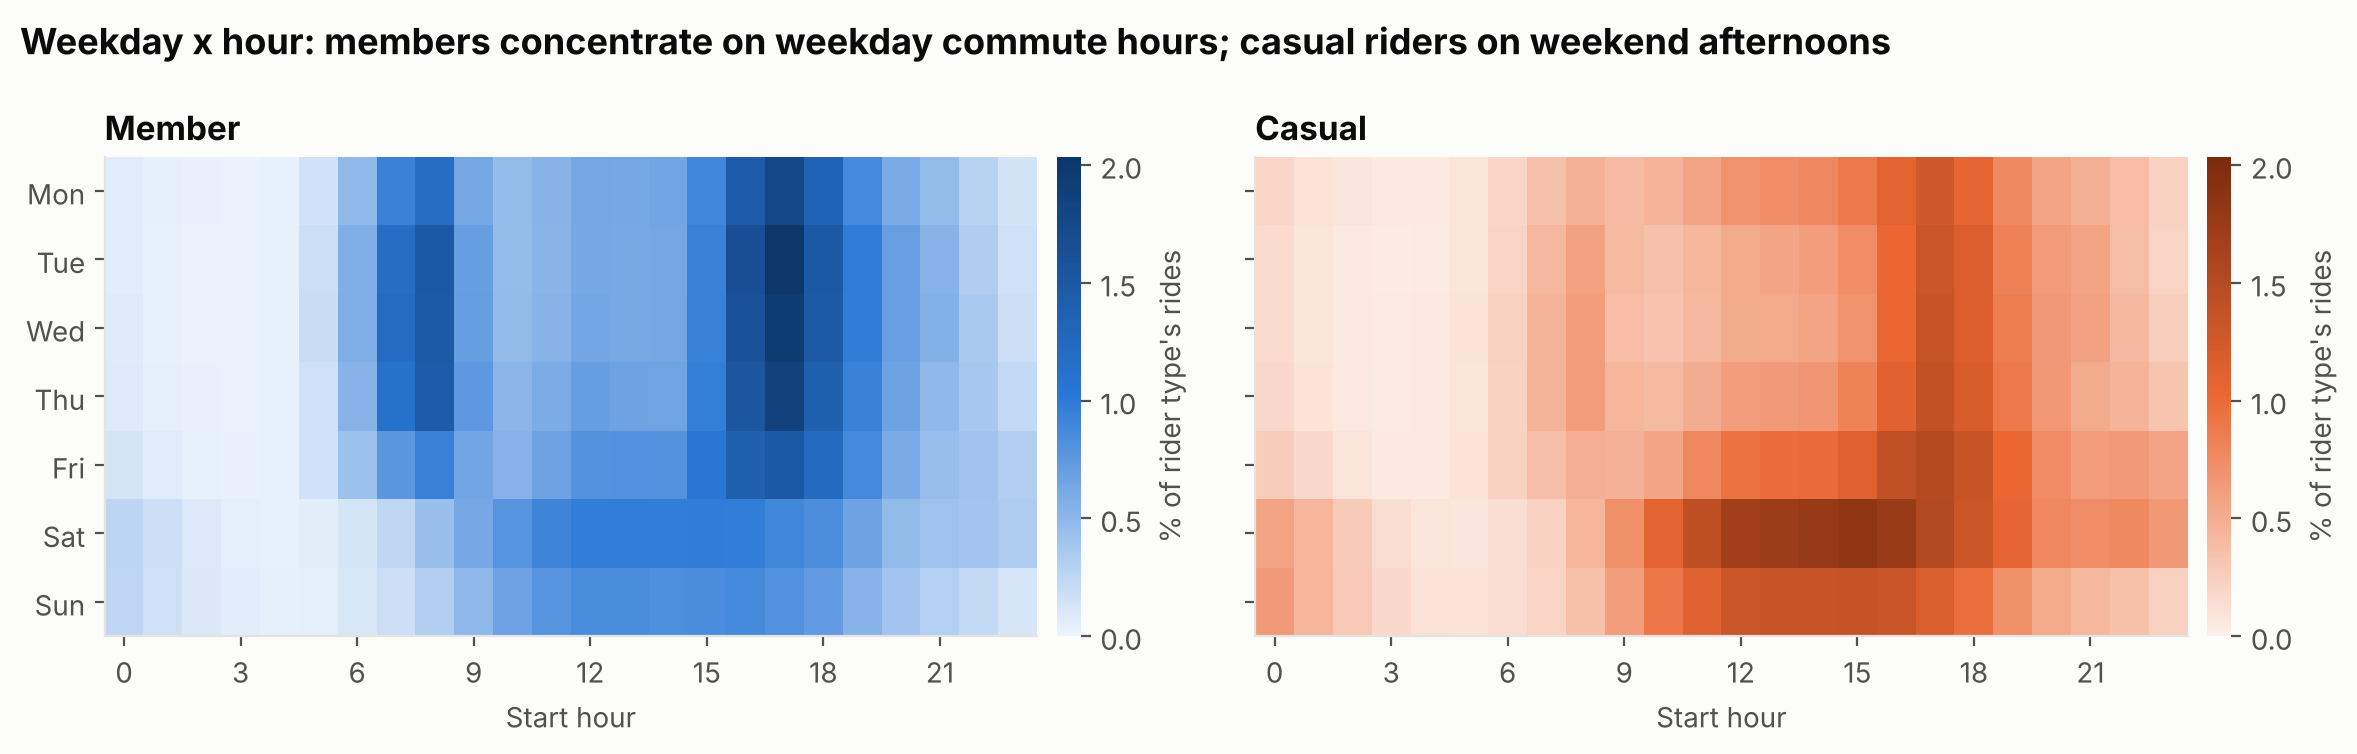

In [7]:
heat = (df.groupby(["member_casual", "day_of_week", "hour"], observed=True).size()
          .rename("rides").reset_index())
heat["share_pct"] = heat["rides"] / heat.groupby("member_casual", observed=True)["rides"].transform("sum") * 100
DAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
vmax = heat["share_pct"].max()

ramps = {"member": LinearSegmentedColormap.from_list("m", ["#eef5fd", "#2a78d6", "#0d366b"]),
         "casual": LinearSegmentedColormap.from_list("c", ["#fdf0ea", "#eb6834", "#7a2a0c"])}

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, rider in zip(axes, ORDER):
    grid = (heat[heat.member_casual == rider]
            .pivot(index="day_of_week", columns="hour", values="share_pct")
            .reindex(DAYS).fillna(0))
    im = ax.imshow(grid.values, aspect="auto", cmap=ramps[rider], vmin=0, vmax=vmax)
    ax.set_title(rider.capitalize()); ax.grid(False)
    ax.set_xticks(range(0, 24, 3)); ax.set_xlabel("Start hour")
    ax.set_yticks(range(7)); ax.set_yticklabels([d[:3] for d in DAYS])
    cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
    cb.set_label("% of rider type's rides", color=INK2); cb.outline.set_visible(False)
fig.suptitle("Weekday x hour: members concentrate on weekday commute hours; casual riders on weekend afternoons",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
save(fig, "02_weekday_hour_heatmap.png")

### 3.2 When: seasonality

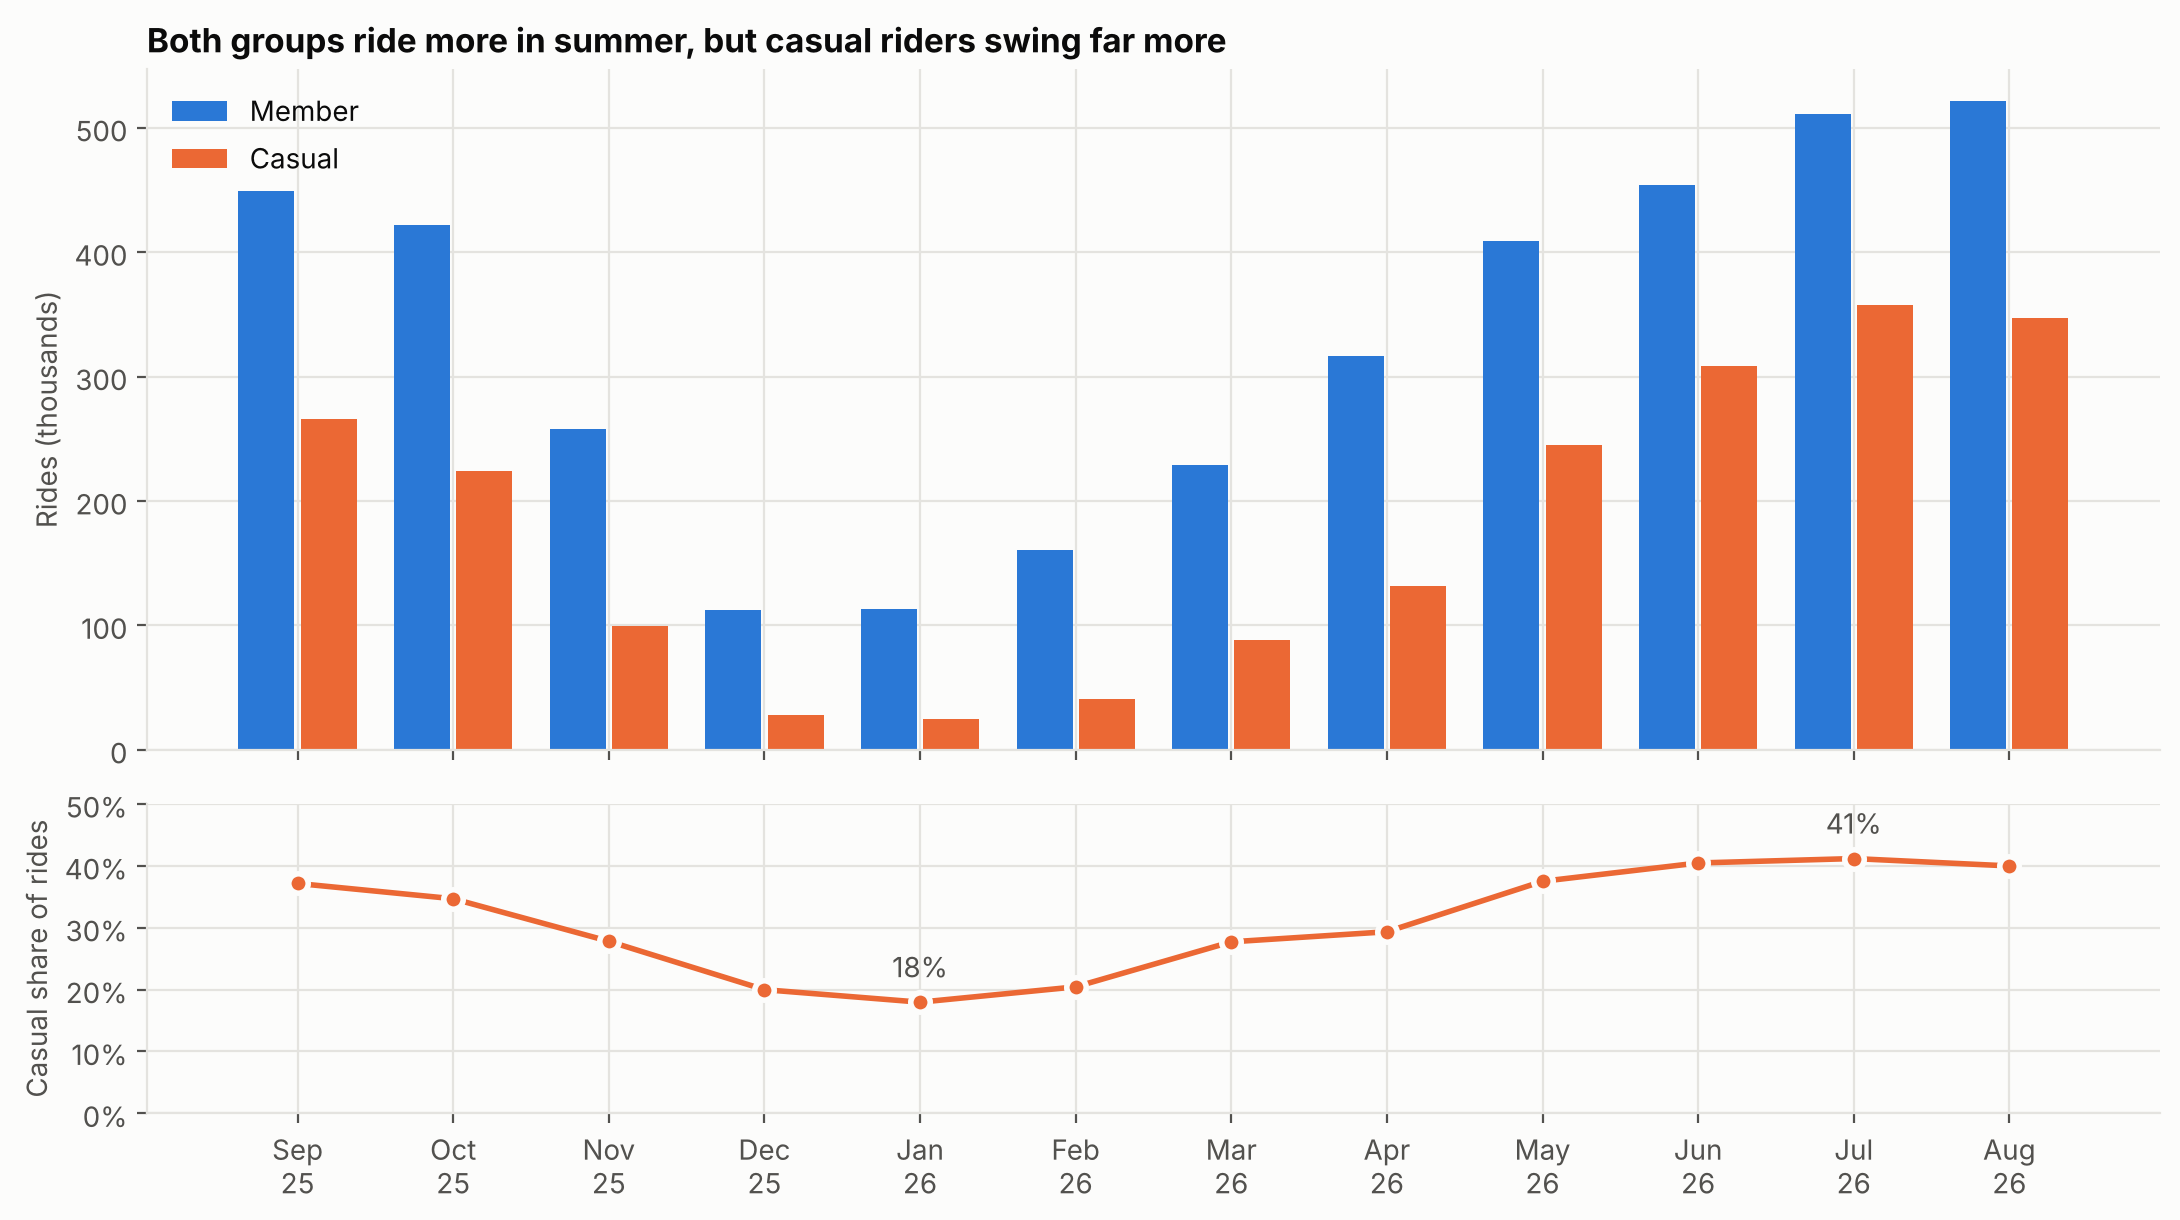

member_casual,member,casual,casual_share_pct
analysis_month,,,
202509,449298,265461,37.14
202510,422029,224010,34.67
202511,257479,99149,27.80
202512,112454,28080,19.98
202601,113038,24749,17.96
202602,160277,41173,20.44
202603,229181,87856,27.71
202604,316715,131502,29.34
202605,408599,245105,37.49


In [8]:
monthly = (df.groupby(["analysis_month", "member_casual"], observed=True).size()
             .unstack().loc[:, ORDER])
monthly["casual_share_pct"] = monthly["casual"] / (monthly["casual"] + monthly["member"]) * 100
labels = pd.to_datetime(monthly.index, format="%Y%m").strftime("%b\n%y")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.2), sharex=True, height_ratios=[2.2, 1])
x = np.arange(len(monthly)); w = 0.36
for i, rider in enumerate(ORDER):
    ax1.bar(x + (i - 0.5) * (w + 0.04), monthly[rider] / 1000, width=w, color=COLOR[rider],
            label=rider.capitalize())
ax1.set_ylabel("Rides (thousands)"); ax1.legend(loc="upper left")
ax1.set_title("Both groups ride more in summer, but casual riders swing far more")
ax2.plot(x, monthly["casual_share_pct"], color=COLOR["casual"], lw=2, solid_capstyle="round")
ax2.plot(x, monthly["casual_share_pct"], "o", color=COLOR["casual"], ms=7, mec=SURFACE, mew=2)
for idx in (monthly["casual_share_pct"].idxmin(), monthly["casual_share_pct"].idxmax()):
    i = list(monthly.index).index(idx); v = monthly.loc[idx, "casual_share_pct"]
    ax2.annotate(f"{v:.0f}%", (i, v), xytext=(0, 9), textcoords="offset points", ha="center", color=INK2)
ax2.set_ylabel("Casual share of rides"); ax2.set_ylim(0, 50)
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax2.set_xticks(x); ax2.set_xticklabels(labels)
fig.tight_layout()
save(fig, "03_monthly_rides_and_casual_share.png")
monthly.round(2)

### 3.3 How long, and on what bike

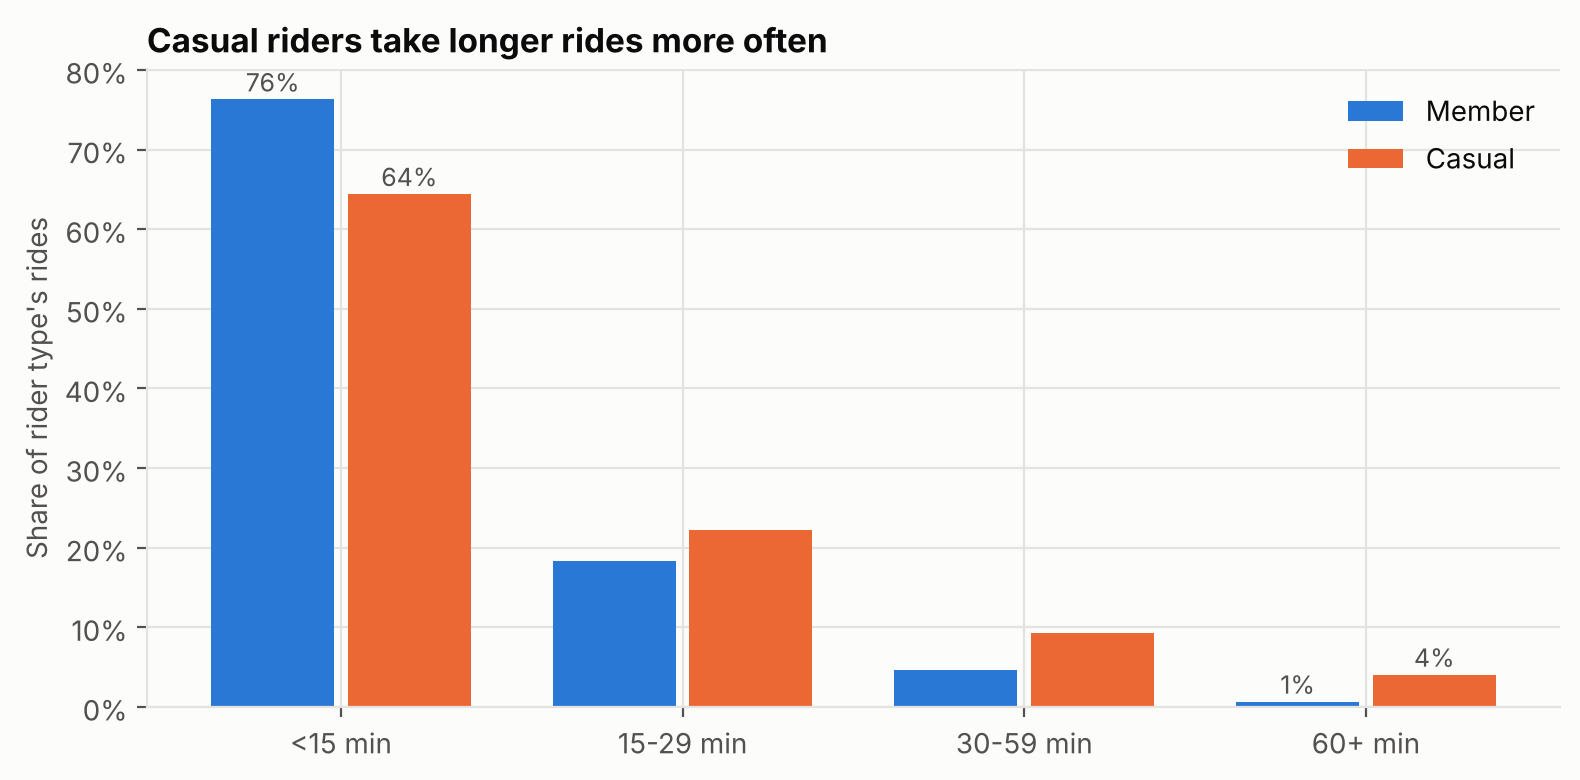

In [9]:
bucket = (df.groupby(["member_casual", "duration_bucket"], observed=True).size()
            .rename("rides").reset_index())
bucket["share_pct"] = bucket["rides"] / bucket.groupby("member_casual", observed=True)["rides"].transform("sum") * 100

fig, ax = plt.subplots(figsize=(8, 4))
cats = list(bucket["duration_bucket"].cat.categories); x = np.arange(len(cats)); w = 0.36
for i, rider in enumerate(ORDER):
    vals = bucket[bucket.member_casual == rider].set_index("duration_bucket").loc[cats, "share_pct"]
    bars = ax.bar(x + (i - 0.5) * (w + 0.04), vals, width=w, color=COLOR[rider], label=rider.capitalize())
    for j in (0, len(cats) - 1):                      # label only the two ends of the scale
        ax.text(bars[j].get_x() + w / 2, vals.iloc[j] + 1, f"{vals.iloc[j]:.0f}%", ha="center",
                fontsize=9, color=INK2)
ax.set_xticks(x); ax.set_xticklabels(cats); ax.set_ylabel("Share of rider type's rides")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax.legend()
ax.set_title("Casual riders take longer rides more often")
fig.tight_layout()
save(fig, "04_duration_distribution.png")

In [10]:
dur = (df.groupby(["member_casual", "rideable_type", "day_type"], observed=True)["ride_length_minutes"]
         .agg(rides="size", mean="mean", median="median", p75=lambda s: s.quantile(0.75)).round(2))
dur.loc[ORDER]

rides   mean  median    p75
member_casual rideable_type day_type                               
member        classic_bike  Weekday    965785  14.73    8.97  15.90
                            Weekend    297737  16.57   10.11  18.41
              electric_bike Weekday   2066686  10.73    8.12  13.38
                            Weekend    625386  12.11    8.87  15.01
casual        classic_bike  Weekday    336996  37.15   14.46  27.88
                            Weekend    233300  43.19   17.88  33.74
              electric_bike Weekday   1018226  12.91    9.02  15.50
                            Weekend    571831  15.69   10.93  19.38

## 4. Duration outliers: how sensitive are the conclusions?

The cleaning plan keeps every ride. Mean duration is pulled up by a small number of very long rides, especially for casual classic-bike riders. This section checks whether the member/casual duration gap survives trimming.

In [11]:
def sensitivity(sub):
    return pd.Series({
        "rides": len(sub),
        "under_1_min_pct": (sub.ride_length_minutes < 1).mean() * 100,
        "over_3_hours_pct": (sub.ride_length_minutes >= 180).mean() * 100,
        "avg_all": sub.ride_length_minutes.mean(),
        "avg_trimmed_1_to_180": sub.ride_length_minutes[sub.ride_length_minutes.between(1, 180, inclusive="left")].mean(),
        "median_all": sub.ride_length_minutes.median(),
    })

sens = df.groupby("member_casual", observed=True).apply(sensitivity, include_groups=False).loc[ORDER].round(2)
display(sens)
gap_all = sens.loc["casual", "avg_all"] / sens.loc["member", "avg_all"]
gap_med = sens.loc["casual", "median_all"] / sens.loc["member", "median_all"]
gap_trim = sens.loc["casual", "avg_trimmed_1_to_180"] / sens.loc["member", "avg_trimmed_1_to_180"]
print(f"Casual/member duration ratio: mean {gap_all:.2f}x | trimmed mean {gap_trim:.2f}x | median {gap_med:.2f}x")

,rides,under_1_min_pct,over_3_hours_pct,avg_all,avg_trimmed_1_to_180,median_all
member_casual,,,,,,
member,3955594.0,2.12,0.14,12.37,11.73,8.55
casual,2160353.0,3.48,0.47,20.70,17.13,10.86


Casual/member duration ratio: mean 1.67x | trimmed mean 1.46x | median 1.27x


## 5. Where do casual riders ride? Stations and round trips

start_station_coverage_pct
member_casual rideable_type                            
casual        classic_bike                        100.0
              electric_bike                        70.3
member        classic_bike                        100.0
              electric_bike                        69.8

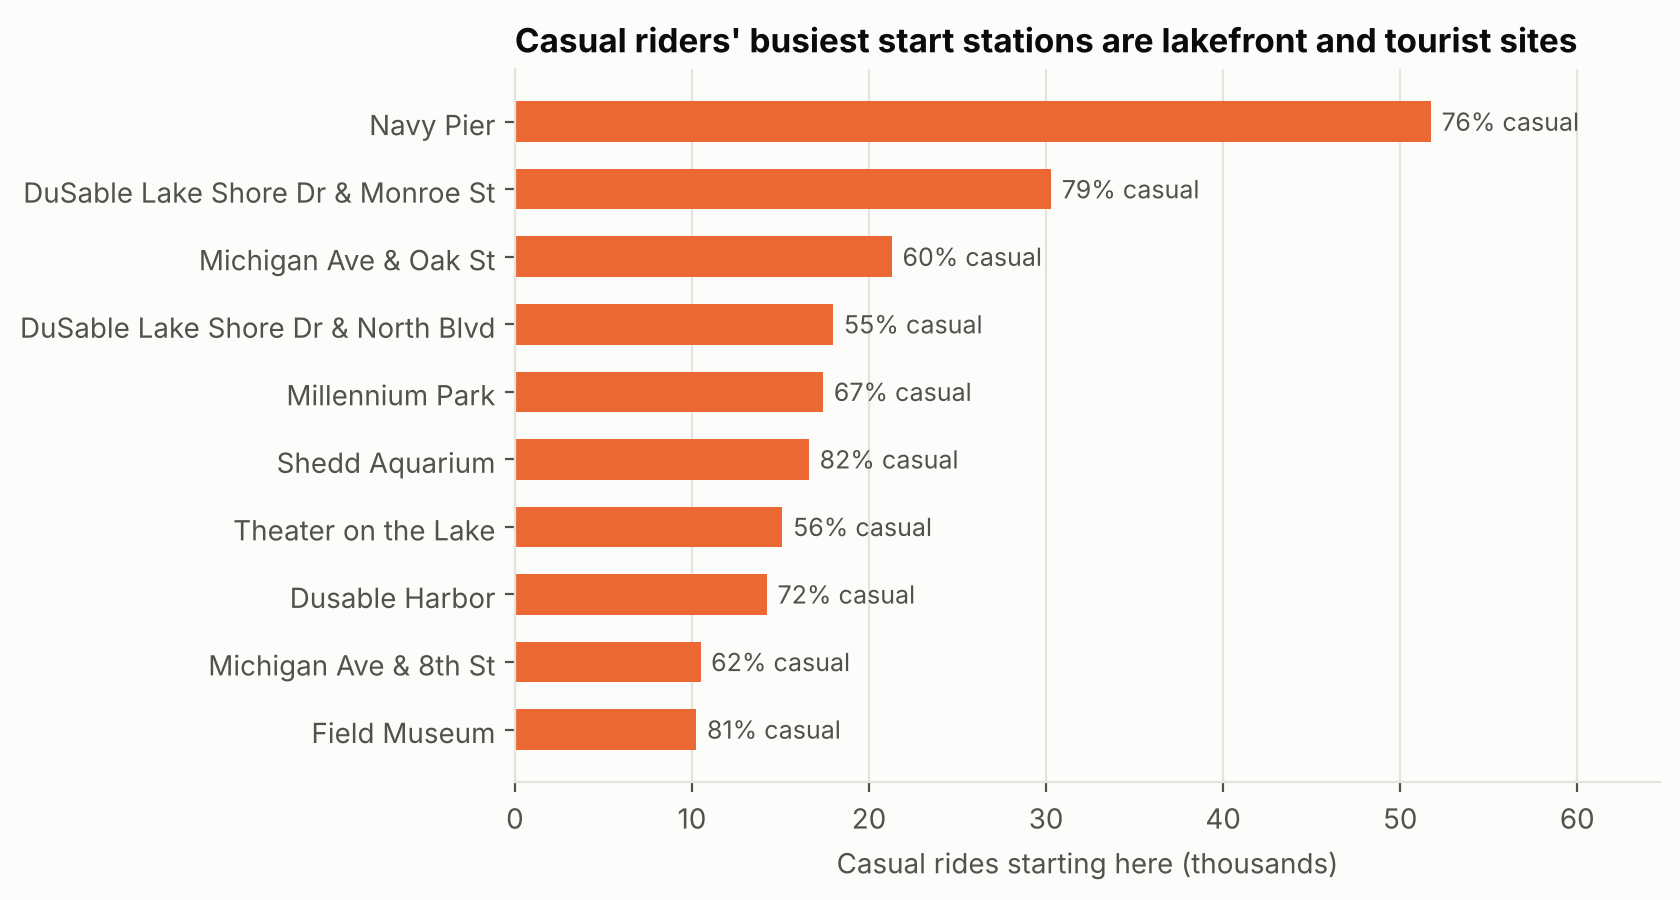

In [12]:
st = df[df["start_station_id"].notna()].copy()
coverage = (df.assign(has_station=df["start_station_id"].notna())
              .groupby(["member_casual", "rideable_type"], observed=True)["has_station"].mean().mul(100).round(1))
display(coverage.rename("start_station_coverage_pct").to_frame())

by_station = (st.groupby("start_station_id", observed=True)
                .agg(name=("start_station_name", "first"),
                     casual=("member_casual", lambda s: (s == "casual").sum()),
                     total=("member_casual", "size")))
by_station["casual_share_pct"] = by_station["casual"] / by_station["total"] * 100
top = by_station.sort_values("casual", ascending=False).head(10).iloc[::-1]

fig, ax = plt.subplots(figsize=(8.5, 4.6))
bars = ax.barh(top["name"].astype(str), top["casual"] / 1000, height=0.6, color=COLOR["casual"])
for b, (_, r) in zip(bars, top.iterrows()):
    ax.text(b.get_width() + 0.6, b.get_y() + b.get_height() / 2,
            f"{r['casual_share_pct']:.0f}% casual", va="center", fontsize=9, color=INK2)
ax.set_xlabel("Casual rides starting here (thousands)"); ax.grid(axis="y", visible=False)
ax.set_xlim(0, top["casual"].max() / 1000 * 1.25)
ax.set_title("Casual riders' busiest start stations are lakefront and tourist sites")
fig.tight_layout()
save(fig, "05_top_casual_stations.png")

In [13]:
both = df[df["start_station_id"].notna() & df["end_station_id"].notna()].copy()
both["round_trip"] = both["start_station_id"].astype(str) == both["end_station_id"].astype(str)
rt = (both.groupby(["member_casual", "rideable_type"], observed=True)
          .agg(rides=("round_trip", "size"), round_trips=("round_trip", "sum"),
               round_trip_pct=("round_trip", lambda s: s.mean() * 100)).round(2))
rt.loc[ORDER]

rides  round_trips  round_trip_pct
member_casual rideable_type                                      
member        classic_bike   1262407        31199            2.47
              electric_bike  1397345        53266            3.81
casual        classic_bike    565924        57879           10.23
              electric_bike   832822        62329            7.48

## 6. Q2/Q3 — What this implies for conversion and digital marketing

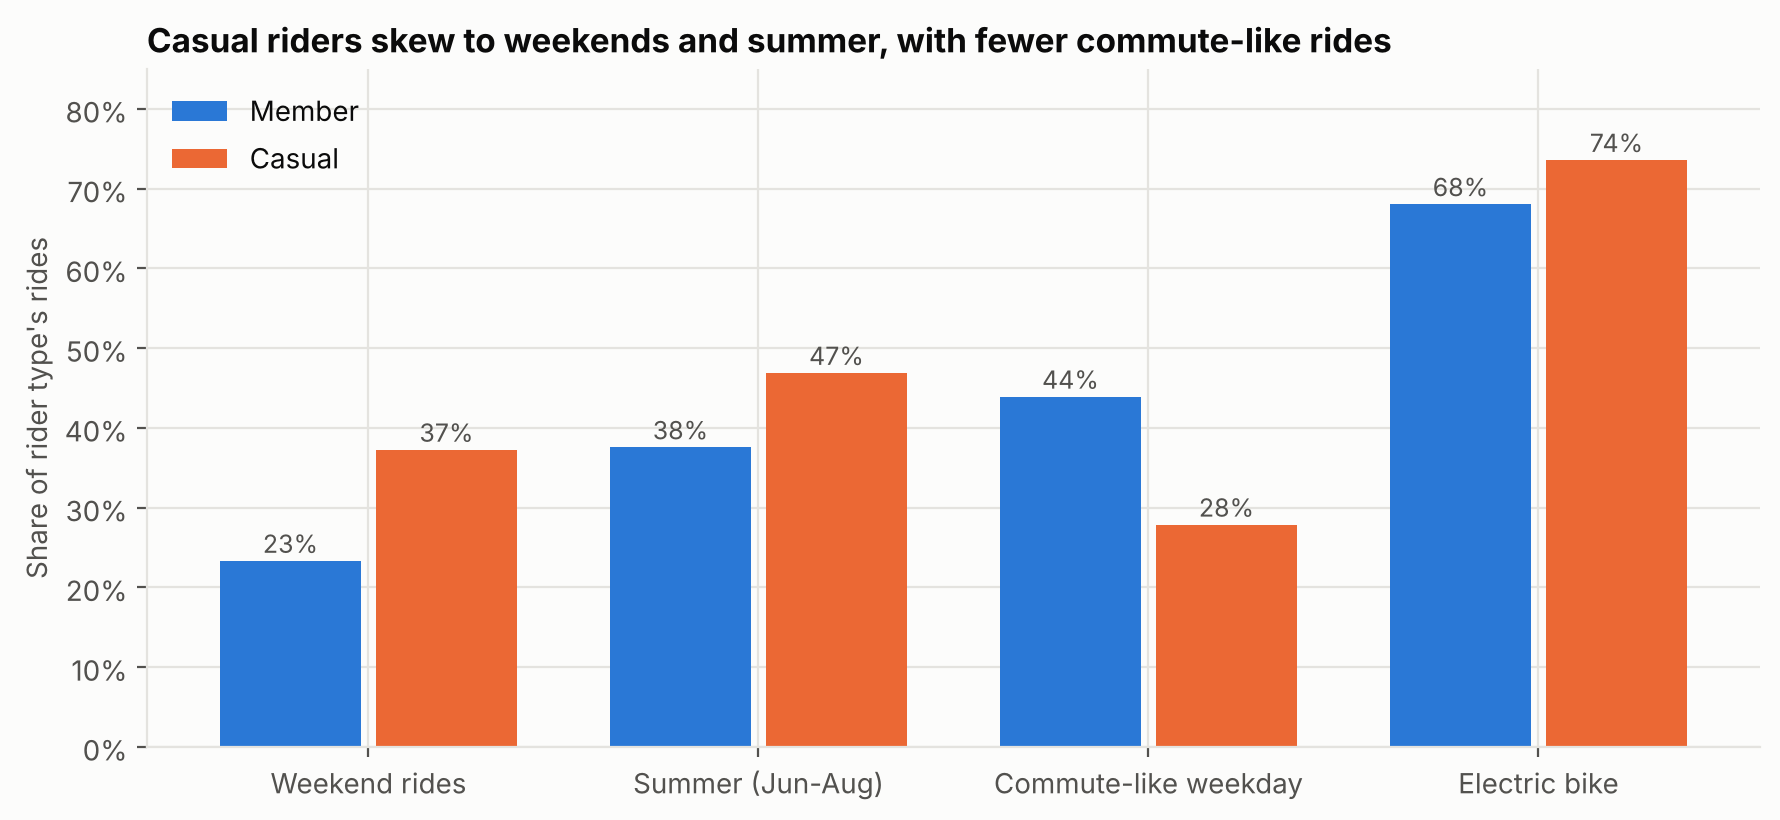

In [14]:
profile = pd.DataFrame({
    "Weekend rides": kpi["weekend_pct"],
    "Summer (Jun-Aug)": kpi["summer_pct"],
    "Commute-like weekday": kpi["commute_like_pct"],
    "Electric bike": kpi["electric_pct"],
}).loc[ORDER]

fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(profile.shape[1]); w = 0.36
for i, rider in enumerate(ORDER):
    bars = ax.bar(x + (i - 0.5) * (w + 0.04), profile.loc[rider], width=w, color=COLOR[rider],
                  label=rider.capitalize())
    for b, v in zip(bars, profile.loc[rider]):
        ax.text(b.get_x() + w / 2, v + 1, f"{v:.0f}%", ha="center", fontsize=9, color=INK2)
ax.set_xticks(x); ax.set_xticklabels(profile.columns)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax.set_ylim(0, 85)
ax.set_ylabel("Share of rider type's rides"); ax.legend()
ax.set_title("Casual riders skew to weekends and summer, with fewer commute-like rides")
fig.tight_layout()
save(fig, "06_behaviour_profile.png")

## 7. Findings summary

In [15]:
k, c = kpi.loc["member"], kpi.loc["casual"]
morning = df[df["hour"].between(6, 9)].groupby("member_casual", observed=True).size() / g.size() * 100
shedd = by_station.loc[by_station["name"].astype(str).eq("Shedd Aquarium")]
casual_share_min, casual_share_max = monthly["casual_share_pct"].min(), monthly["casual_share_pct"].max()
top10_share = by_station.sort_values("casual", ascending=False).head(10)["casual"].sum() / df["member_casual"].eq("casual").sum() * 100
hi = by_station[by_station["total"] >= 5000].sort_values("casual_share_pct", ascending=False).head(15)

display(Markdown(f'''
**Scale.** {int(k.rides + c.rides):,} rides (Sep 2025 - Aug 2026): members {k.ride_share_pct:.1f}%, casual {c.ride_share_pct:.1f}%.

**1. Different rhythms.** Both groups peak at 17:00 on weekdays, but members have a pronounced morning peak: {morning["member"]:.0f}% of member rides start 06:00-09:59 versus {morning["casual"]:.0f}% of casual rides. {k.commute_like_pct:.0f}% of member rides are commute-like (weekday, commute window, under 30 min) versus {c.commute_like_pct:.0f}% of casual rides. {c.weekend_pct:.0f}% of casual rides fall on weekends (members: {k.weekend_pct:.0f}%). Weekend hourly profiles are nearly identical; the difference there is volume, not timing.

**2. Seasonality is much stronger for casual riders.** {c.summer_pct:.0f}% of casual rides happen in June-August (members: {k.summer_pct:.0f}%). Casual share of all rides ranges from {casual_share_min:.0f}% in the winter low to {casual_share_max:.0f}% at the summer peak.

**3. Longer, more variable rides.** Median ride: casual {c.median_min:.1f} min vs member {k.median_min:.1f} min ({gap_med:.2f}x). The gap in mean is larger ({gap_all:.2f}x) because of long rides; after trimming rides under 1 min and over 3 h it is {gap_trim:.2f}x. The direction holds under every treatment.

**4. Leisure geography, but dispersed.** Casual riders are the majority at lakefront and tourist stations (e.g. Shedd Aquarium: {shedd["casual_share_pct"].iloc[0]:.0f}% casual; all {len(hi)} highest-casual-share stations are at least {hi["casual_share_pct"].min():.0f}% casual). Yet the ten busiest casual stations hold only {top10_share:.0f}% of all casual rides, and casual riders also make round trips more often ({rt.loc[("casual","classic_bike"),"round_trip_pct"]:.0f}% of classic-bike rides vs {rt.loc[("member","classic_bike"),"round_trip_pct"]:.0f}% for members). Station-specific promotion reaches a minority of casual riders; timing- and season-based targeting reaches more.

**5. Bike type is not the differentiator.** Electric share is similar ({c.electric_pct:.0f}% casual vs {k.electric_pct:.0f}% member).
'''))


**Scale.** 6,115,947 rides (Sep 2025 - Aug 2026): members 64.7%, casual 35.3%.

**1. Different rhythms.** Both groups peak at 17:00 on weekdays, but members have a pronounced morning peak: 20% of member rides start 06:00-09:59 versus 11% of casual rides. 44% of member rides are commute-like (weekday, commute window, under 30 min) versus 28% of casual rides. 37% of casual rides fall on weekends (members: 23%). Weekend hourly profiles are nearly identical; the difference there is volume, not timing.

**2. Seasonality is much stronger for casual riders.** 47% of casual rides happen in June-August (members: 38%). Casual share of all rides ranges from 18% in the winter low to 41% at the summer peak.

**3. Longer, more variable rides.** Median ride: casual 10.9 min vs member 8.6 min (1.27x). The gap in mean is larger (1.67x) because of long rides; after trimming rides under 1 min and over 3 h it is 1.46x. The direction holds under every treatment.

**4. Leisure geography, but dispersed.** Casual riders are the majority at lakefront and tourist stations (e.g. Shedd Aquarium: 82% casual; all 15 highest-casual-share stations are at least 55% casual). Yet the ten busiest casual stations hold only 10% of all casual rides, and casual riders also make round trips more often (10% of classic-bike rides vs 2% for members). Station-specific promotion reaches a minority of casual riders; timing- and season-based targeting reaches more.

**5. Bike type is not the differentiator.** Electric share is similar (74% casual vs 68% member).


### Limitations

- **No rider IDs.** Rides are not people. The data cannot show how many distinct casual riders exist, how often each rides, or whether any would convert. Behavioural similarity to members is an *opportunity signal*, not a conversion forecast.
- **No pricing or revenue data.** The Ask phase lists membership revenue and conversion rate as metrics; neither can be computed from this dataset.
- **No trip purpose.** "Commute-like" describes timing and length only.
- **Station data is incomplete.** About 30% of electric-bike rides have no start station, so station and round-trip results describe the rides that do.
- **Casual share depends on the sample year** (one 12-month window).

### Next step
Take the SQL result tables into Power BI for the interactive dashboard, then write the final report.